# Nuages de mots

## Imports et stopwords

In [1]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Fatig\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [25]:
# Stopwords 
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", "très","près", "année",
       "leurs", "jeudi", "août", "bon", "ans", "lux", "gar", "bur", "chez", "chb", "ecr", 
       "saint", "tél", "soir", "terr", "mercredi", "dimanche", "lundi", "mardi", "vendredi", 
       "samedi", "janvier", "février", "semaine", "mod", "avril", "quelques", "octobre", 
       "année", "heures", "prés", "cuis", "conf", "grand", "liv", "téléph"] 
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [26]:
# Choisir une année
year = 1969

In [27]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [28]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [29]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [30]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"t Dt» LE SOIR b Bourse de Bruxelles VENDREDI 3 JANVIER Marché toujours soutenu' L'activité est moins étoffée que la Veille et quelques prises de bénéfices donnent à la cote une physionomie moins uniformément favorable. Toutefois, plusieurs points de soutien, voire de fermeté, subsistent, tant en Valeurs locales qu’en titres étrangers. Parmi ces derniers, les non- ferreux demeurent très entourés. La demande de Londres est assez importante en R. S. T., 662, et en Zam- blan Anglo où l’ancienne pass"

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage

In [31]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [32]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1969_clean.txt!'

In [33]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'BOURSE BRUXELLES MARCHÉ TOUJOURS SOUTENU ACTIVITÉ ÉTOFFÉE VEILLE PRISES BÉNÉFICES DONNENT COTE PHYSIONOMIE UNIFORMÉMENT FAVORABLE TOUTEFOIS PLUSIEURS POINTS SOUTIEN VOIRE FERMETÉ SUBSISTENT TANT VALEURS LOCALES TITRES ÉTRANGERS PARMI DERNIERS FERREUX DEMEURENT ENTOURÉS DEMANDE LONDRES ASSEZ IMPORTANTE ZAM BLAN ANGLO ANCIENNE PASSE NOUVELLE AURIFÈRES HAUSSE CITY ACCENTUENT AVANCE SURTOUT RAND MINES BRAND PARMI VALEURS BELGES AMÉLIORATION APPRÉCIABLE ENREGISTRÉE PÉTROFINA VALEURS ÉTRANGÈRES GROUPE'

## Nuage de mots

### Créer, stocker et afficher le nuage de mots

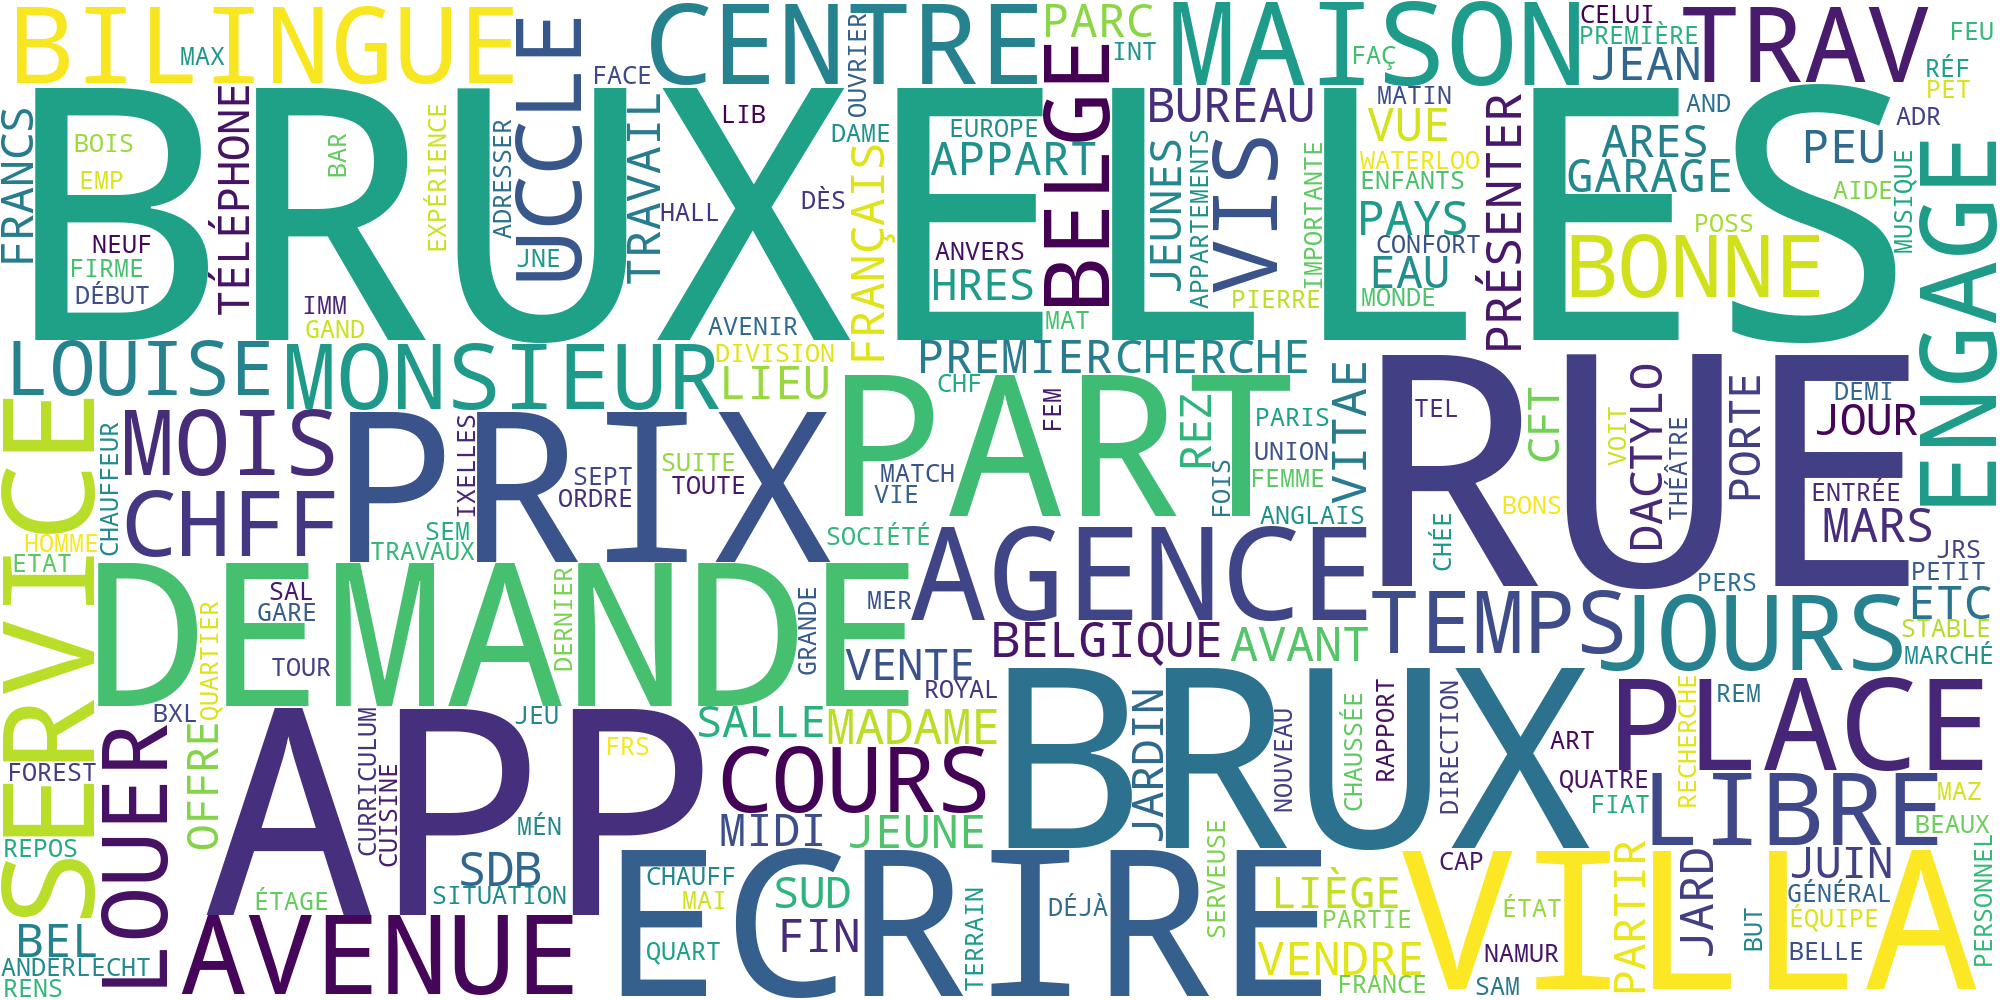

In [34]:
frequencies = Counter(after.split())
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))